In [1]:
#!pip install vaderSentiment

In [2]:
#pip install wordcloud

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from colorama import Fore, init
import plotly.express as px

import string
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk import tokenize
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from tqdm.notebook import tqdm
from collections import Counter
from wordcloud import WordCloud



nltk.download('vader_lexicon')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger')

import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [4]:
# Read in data
df = pd.read_csv(r'C:\Users\Admin\Desktop\Tamuct MSIS Courses\Spring 2024\Web & Social Analytics_CIS-5356-115\Project\GV_Sentiment Analysis_Modified.csv', engine='python', encoding='latin1')
print(df.shape)
df = df.head(500)
print(df.shape)

(732, 5)
(500, 5)


In [5]:
df.head()

,Text,Sentiment,Platform,Country,Year
0,Enjoying a beautiful day at the park! ...,Positive,Twitter,USA,2023
1,Traffic was terrible this morning. ...,Negative,Twitter,Canada,2023
2,Just finished an amazing workout! ðª ...,Positive,Instagram,USA,2023
3,Excited about the upcoming weekend getaway! ...,Positive,Facebook,UK,2023
4,Trying out a new recipe for dinner tonight. ...,Neutral,Instagram,Australia,2023


In [6]:
def null_count():
    return pd.DataFrame({'features': df.columns,
                'dtypes': df.dtypes.values,
                'NaN count': df.isnull().sum().values,
                'NaN percentage': df.isnull().sum().values/df.shape[0]}).style.background_gradient(cmap='Set3',low=0.1,high=0.01)
null_count()

,features,dtypes,NaN count,NaN percentage
0,Text,object,0,0.000000
1,Sentiment,object,0,0.000000
2,Platform,object,0,0.000000
3,Country,object,0,0.000000
4,Year,int64,0,0.000000


In [7]:
df.duplicated().sum()

21

In [8]:
df.columns

Index(['Text', 'Sentiment', 'Platform', 'Country', 'Year'], dtype='object')

In [9]:
for column in df.columns:
    num_distinct_values = len(df[column].unique())
    print(f"{column}: {num_distinct_values} distinct values")

Text: 475 distinct values
Sentiment: 219 distinct values
Platform: 4 distinct values
Country: 101 distinct values
Year: 14 distinct values


In [10]:
#df = df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0', 'Hashtags','Day', 'Hour'])

In [11]:
# check 'Sentiment'
df['Sentiment'].value_counts()

 Positive          44
 Hopeful            9
 Loneliness         7
 Elation            6
 Playful            6
                   ..
 Anticipation       1
 Blessed            1
 Satisfaction       1
 Excitement         1
 Romance            1
Name: Sentiment, Length: 219, dtype: int64

In [12]:
# check 'Platform'
df['Platform'].value_counts()

 Instagram     175
 Facebook      161
 Twitter       115
 Twitter        49
Name: Platform, dtype: int64

In [13]:
# check 'Country'
df['Country'].value_counts()

 Australia             37
 USA                   33
 Canada                28
 UK                    24
 USA                   20
                       ..
 Japan                  1
 Canada                 1
 France                 1
 Australia              1
 Peru                   1
Name: Country, Length: 101, dtype: int64

In [14]:
df1 = df.copy()

In [15]:
#Clean text
stopword = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean(text):
    text = str(text).lower()
    text = re.sub('\[.*?\]', '', text)
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    text = [word for word in text.split(' ') if word not in stopword]
    #text = [stemmer.stem(word) for word in text]
    text = " ".join(text)
    
    return text

df1['Clean_Text']=df1['Text'].map(lambda s:clean(s)) 
#df1["Clean_Text"] = df1["Text"].apply(clean)

In [16]:
# Remove symbols from text
df1['Clean_Text'] = df1['Clean_Text'].apply(lambda text: re.sub(r'[^\w\s]', '', str(text)))

In [17]:
def remove_special_characters(text):
    # Using regular expression to remove non-alphanumeric characters and whitespace
    return re.sub(r'[^a-zA-Z0-9\s]', '', str(text))

# Remove special characters from text
df1['Clean_Text'] = df1['Clean_Text'].apply(remove_special_characters)

In [18]:
df1

,Text,Sentiment,Platform,Country,Year,Clean_Text
0,Enjoying a beautiful day at the park! ...,Positive,Twitter,USA,2023,enjoying beautiful day park
1,Traffic was terrible this morning. ...,Negative,Twitter,Canada,2023,traffic terrible morning
2,Just finished an amazing workout! ðª ...,Positive,Instagram,USA,2023,finished amazing workout
3,Excited about the upcoming weekend getaway! ...,Positive,Facebook,UK,2023,excited upcoming weekend getaway
4,Trying out a new recipe for dinner tonight. ...,Neutral,Instagram,Australia,2023,trying new recipe dinner tonight
...,...,...,...,...,...,...
495,"In the embrace of the Grand Canyon, nature's m...",Awe,Instagram,USA,2020,embrace grand canyon natures masterpiece momen...
496,"Journeying through the serenity of Santorini, ...",Serenity,Facebook,Greece,2016,journeying serenity santorini sunset paints sk...
497,"Amazed by the architectural marvels of Petra, ...",Amazement,Twitter,Jordan,2023,amazed architectural marvels petra stone telli...
498,"Embarking on a gondola ride in Venice, each ca...",Romance,Instagram,Italy,2019,embarking gondola ride venice canal reflecting...


In [19]:
print(df1[['Text','Clean_Text']].head())

                                                Text  \
0   Enjoying a beautiful day at the park!        ...   
1   Traffic was terrible this morning.           ...   
2   Just finished an amazing workout! ðª       ...   
3   Excited about the upcoming weekend getaway!  ...   
4   Trying out a new recipe for dinner tonight.  ...   

                                   Clean_Text  
0   enjoying beautiful day park                
1   traffic terrible morning                   
2    finished amazing workout                  
3    excited upcoming weekend getaway          
4    trying new recipe dinner tonight          


In [20]:
df1.to_csv('sentiment_analysis_results.csv', index=False)

In [21]:
df2 = pd.read_csv(r'C:\Users\Admin\Desktop\Tamuct MSIS Courses\Spring 2024\Web & Social Analytics_CIS-5356-115\Project\Final_sentiment_analysis_results.csv', engine='python', encoding='latin1')
df2

,Clean_Text,Sentiment,Platform,Country,Year
0,enjoying beautiful day park,Positive,Twitter,USA,2023
1,traffic terrible morning,Negative,Twitter,Canada,2023
2,finished amazing workout,Positive,Instagram,USA,2023
3,excited upcoming weekend getaway,Positive,Facebook,UK,2023
4,trying new recipe dinner tonight,Neutral,Instagram,Australia,2023
...,...,...,...,...,...
495,embrace grand canyon natures masterpiece momen...,Awe,Instagram,USA,2020
496,journeying serenity santorini sunset paints sk...,Serenity,Facebook,Greece,2016
497,amazed architectural marvels petra stone telli...,Amazement,Twitter,Jordan,2023
498,embarking gondola ride venice canal reflecting...,Romance,Instagram,Italy,2019


In [22]:
#Sentiment analys
#analyzer = SentimentIntensityAnalyzer()

#df1['Vader_Score'] = df1['Clean_Text'].apply(lambda text: analyzer.polarity_scores(text)['compound'])

#df1['Vader_Sentiment'] = df1['Vader_Score'].apply(lambda score: 'positive' if score >= 0.05 else ('negative' if score <= -0.05 else 'neutral'))

#print(df1[['Clean_Text', 'Vader_Score', 'Vader_Sentiment']].head())

In [23]:
#df1["Clean_Text"] = df1["Text"].apply(clean)
#print(df1['Clean_Text'].head())

In [24]:
#Sentiment Intensity Analyzer
import vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

In [25]:
#Polarity scores
df2['polarity'] = df2['Clean_Text'].apply(lambda x: analyzer.polarity_scores(x))
df2.head(20)

,Clean_Text,Sentiment,Platform,Country,Year,polarity
0,enjoying beautiful day park,Positive,Twitter,USA,2023,"{'neg': 0.0, 'neu': 0.215, 'pos': 0.785, 'comp..."
1,traffic terrible morning,Negative,Twitter,Canada,2023,"{'neg': 0.608, 'neu': 0.392, 'pos': 0.0, 'comp..."
2,finished amazing workout,Positive,Instagram,USA,2023,"{'neg': 0.0, 'neu': 0.345, 'pos': 0.655, 'comp..."
3,excited upcoming weekend getaway,Positive,Facebook,UK,2023,"{'neg': 0.0, 'neu': 0.556, 'pos': 0.444, 'comp..."
4,trying new recipe dinner tonight,Neutral,Instagram,Australia,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound..."
5,feeling grateful little things life,Positive,Twitter,India,2023,"{'neg': 0.0, 'neu': 0.4, 'pos': 0.6, 'compound..."
6,rainy days call cozy blankets hot cocoa,Positive,Facebook,Canada,2023,"{'neg': 0.178, 'neu': 0.822, 'pos': 0.0, 'comp..."
7,new movie release mustwatch,Positive,Instagram,USA,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound..."
8,political discussions heating timeline,Negative,Twitter,USA,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound..."
9,missing summer vibes beach days,Neutral,Facebook,Australia,2023,"{'neg': 0.355, 'neu': 0.645, 'pos': 0.0, 'comp..."


In [26]:
df2['compound'] = df2['polarity'].apply(lambda score_dict: score_dict['compound'])
df2

,Clean_Text,Sentiment,Platform,Country,Year,polarity,compound
0,enjoying beautiful day park,Positive,Twitter,USA,2023,"{'neg': 0.0, 'neu': 0.215, 'pos': 0.785, 'comp...",0.8074
1,traffic terrible morning,Negative,Twitter,Canada,2023,"{'neg': 0.608, 'neu': 0.392, 'pos': 0.0, 'comp...",-0.4767
2,finished amazing workout,Positive,Instagram,USA,2023,"{'neg': 0.0, 'neu': 0.345, 'pos': 0.655, 'comp...",0.5859
3,excited upcoming weekend getaway,Positive,Facebook,UK,2023,"{'neg': 0.0, 'neu': 0.556, 'pos': 0.444, 'comp...",0.3400
4,trying new recipe dinner tonight,Neutral,Instagram,Australia,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000
...,...,...,...,...,...,...,...
495,embrace grand canyon natures masterpiece momen...,Awe,Instagram,USA,2020,"{'neg': 0.0, 'neu': 0.204, 'pos': 0.796, 'comp...",0.9393
496,journeying serenity santorini sunset paints sk...,Serenity,Facebook,Greece,2016,"{'neg': 0.0, 'neu': 0.714, 'pos': 0.286, 'comp...",0.4215
497,amazed architectural marvels petra stone telli...,Amazement,Twitter,Jordan,2023,"{'neg': 0.0, 'neu': 0.53, 'pos': 0.47, 'compou...",0.7351
498,embarking gondola ride venice canal reflecting...,Romance,Instagram,Italy,2019,"{'neg': 0.0, 'neu': 0.69, 'pos': 0.31, 'compou...",0.5574


In [27]:
def Sentiment(x):
    if x>= 0.05:
        return 0 #"Positive"
    elif x<= -0.05:
        return 2 #"Negative"
    else:
        return 1 #"Neutral"
df2['Sentiment'] = df2['compound'].apply(lambda c: 'positive' if c >=0.00 else 'negative')
df2['Sentiment'] = df2['compound'].apply(Sentiment)

In [28]:
df2.head()

,Clean_Text,Sentiment,Platform,Country,Year,polarity,compound
0,enjoying beautiful day park,0,Twitter,USA,2023,"{'neg': 0.0, 'neu': 0.215, 'pos': 0.785, 'comp...",0.8074
1,traffic terrible morning,2,Twitter,Canada,2023,"{'neg': 0.608, 'neu': 0.392, 'pos': 0.0, 'comp...",-0.4767
2,finished amazing workout,0,Instagram,USA,2023,"{'neg': 0.0, 'neu': 0.345, 'pos': 0.655, 'comp...",0.5859
3,excited upcoming weekend getaway,0,Facebook,UK,2023,"{'neg': 0.0, 'neu': 0.556, 'pos': 0.444, 'comp...",0.3400
4,trying new recipe dinner tonight,1,Instagram,Australia,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000


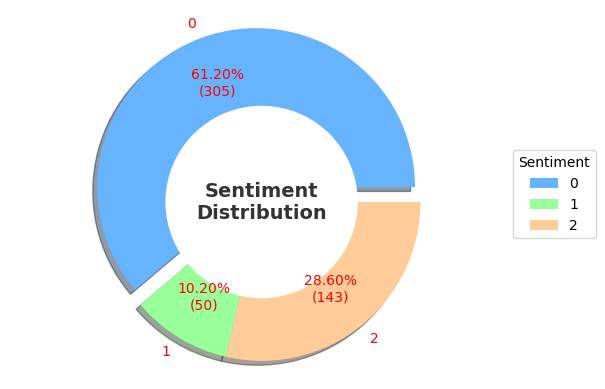

In [29]:
colors = ['#66b3ff', '#99ff99', '#ffcc99']

explode = (0.1, 0, 0)  

sentiment_counts = df2.groupby("Sentiment").size()

fig, ax = plt.subplots()

wedges, texts, autotexts = ax.pie(
    x=sentiment_counts, 
    labels=sentiment_counts.index,
    autopct=lambda p: f'{p:.2f}%\n({int(p*sum(sentiment_counts)/100)})', 
    wedgeprops=dict(width=0.7),
    textprops=dict(size=10, color="r"),  
    pctdistance=0.7,
    colors=colors,
    explode=explode,
    shadow=True)

center_circle = plt.Circle((0, 0), 0.6, color='white', fc='white', linewidth=1.25)
fig.gca().add_artist(center_circle)

ax.text(0, 0, 'Sentiment\nDistribution', ha='center', va='center', fontsize=14, fontweight='bold', color='#333333')

ax.legend(sentiment_counts.index, title="Sentiment", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

ax.axis('equal')  

plt.show()

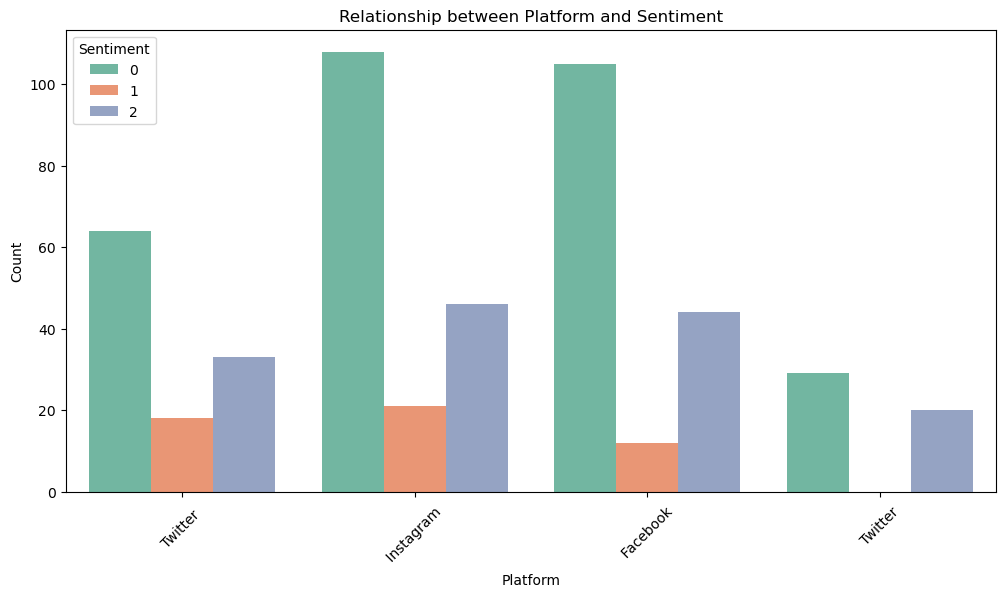

In [30]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Platform', hue='Sentiment', data=df2, palette='Set2')
plt.title('Relationship between Platform and Sentiment')
plt.xlabel('Platform')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

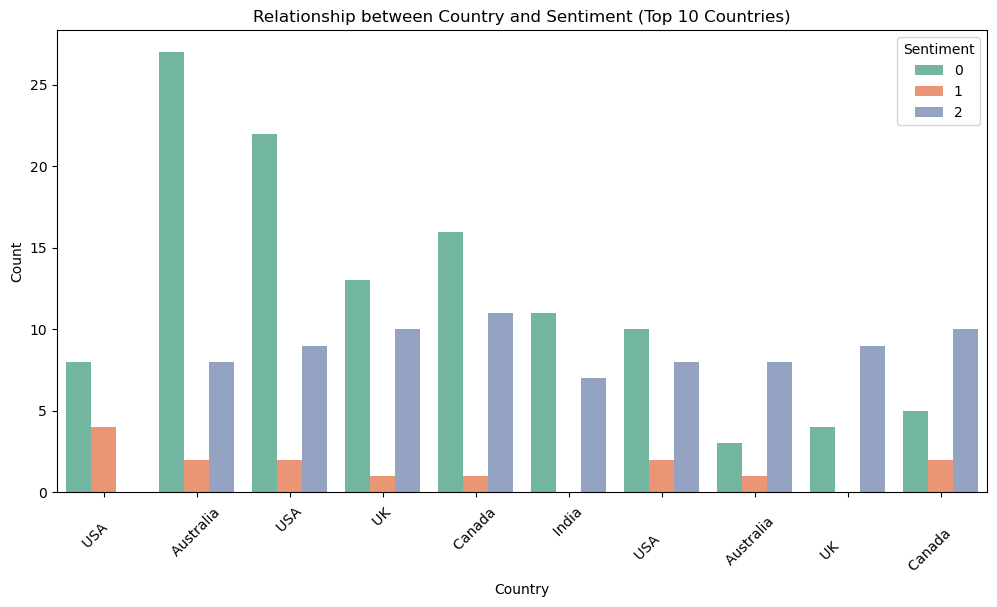

In [31]:
plt.figure(figsize=(12, 6))

top_10_countries = df1['Country'].value_counts().head(10).index

df_top_10_countries = df2[df2['Country'].isin(top_10_countries)]

sns.countplot(x='Country', hue='Sentiment', data=df_top_10_countries, palette='Set2')
plt.title('Relationship between Country and Sentiment (Top 10 Countries)')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

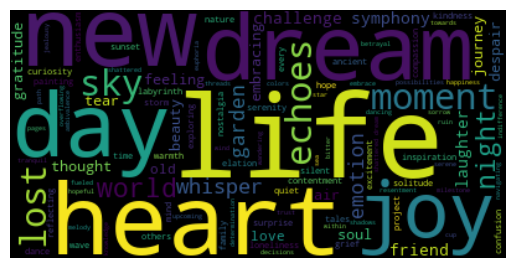

In [32]:
text = " ".join(i for i in df2.Clean_Text)
wordcloud = WordCloud().generate(text)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [33]:
df2['temp_list'] = df2['Clean_Text'].apply(lambda x: str(x).split())
top_words = Counter([item for sublist in df2['temp_list'] for item in sublist])
top_words_df = pd.DataFrame(top_words.most_common(20), columns=['Common_words', 'count'])

top_words_df.style.background_gradient(cmap='Blues')

,Common_words,count
0,dreams,25
1,new,21
2,like,21
3,heart,20
4,laughter,19
5,day,16
6,life,16
7,sky,16
8,echoes,16
9,lost,16


In [34]:
import nltk
from nltk.tokenize import RegexpTokenizer
tokenizer = RegexpTokenizer(r'\w+')
df2['tok_unigram'] = df2['Clean_Text'].apply(tokenizer.tokenize)
df2.head()

import nltk
from nltk.util import ngrams
def ngramconvert(df2,n=3):
    for item in df2.columns:
        df2['bigram']=df2[item].apply(lambda sentence: list(ngrams(sentence.split(), n)))
        return df2

df2 = ngramconvert(df2,2)
df2.head()

import nltk

from nltk.util import ngrams
def ngramconvert(df2,n=3):
    for item in df2.columns:
        df2['trigram']=df2[item].apply(lambda sentence: list(ngrams(sentence.split(), n)))
        return df2

df2 = ngramconvert(df2,3)
df2.head()

,Clean_Text,Sentiment,Platform,Country,Year,polarity,compound,temp_list,tok_unigram,bigram,trigram
0,enjoying beautiful day park,0,Twitter,USA,2023,"{'neg': 0.0, 'neu': 0.215, 'pos': 0.785, 'comp...",0.8074,"[enjoying, beautiful, day, park]","[enjoying, beautiful, day, park]","[(enjoying, beautiful), (beautiful, day), (day...","[(enjoying, beautiful, day), (beautiful, day, ..."
1,traffic terrible morning,2,Twitter,Canada,2023,"{'neg': 0.608, 'neu': 0.392, 'pos': 0.0, 'comp...",-0.4767,"[traffic, terrible, morning]","[traffic, terrible, morning]","[(traffic, terrible), (terrible, morning)]","[(traffic, terrible, morning)]"
2,finished amazing workout,0,Instagram,USA,2023,"{'neg': 0.0, 'neu': 0.345, 'pos': 0.655, 'comp...",0.5859,"[finished, amazing, workout]","[finished, amazing, workout]","[(finished, amazing), (amazing, workout)]","[(finished, amazing, workout)]"
3,excited upcoming weekend getaway,0,Facebook,UK,2023,"{'neg': 0.0, 'neu': 0.556, 'pos': 0.444, 'comp...",0.3400,"[excited, upcoming, weekend, getaway]","[excited, upcoming, weekend, getaway]","[(excited, upcoming), (upcoming, weekend), (we...","[(excited, upcoming, weekend), (upcoming, week..."
4,trying new recipe dinner tonight,1,Instagram,Australia,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,"[trying, new, recipe, dinner, tonight]","[trying, new, recipe, dinner, tonight]","[(trying, new), (new, recipe), (recipe, dinner...","[(trying, new, recipe), (new, recipe, dinner),..."


In [36]:
# Perform POS tagging
def pos_tagging(text):
    tokens = nltk.word_tokenize(text)  # Tokenize the text
    pos_tags = nltk.pos_tag(tokens)    # Perform POS tagging
    return pos_tags

# Apply POS tagging to the 'Clean Text' column
df2['POS Tags'] = df2['Clean_Text'].apply(pos_tagging)
df2.head()

,Clean_Text,Sentiment,Platform,Country,Year,polarity,compound,temp_list,tok_unigram,bigram,trigram,POS Tags
0,enjoying beautiful day park,0,Twitter,USA,2023,"{'neg': 0.0, 'neu': 0.215, 'pos': 0.785, 'comp...",0.8074,"[enjoying, beautiful, day, park]","[enjoying, beautiful, day, park]","[(enjoying, beautiful), (beautiful, day), (day...","[(enjoying, beautiful, day), (beautiful, day, ...","[(enjoying, VBG), (beautiful, JJ), (day, NN), ..."
1,traffic terrible morning,2,Twitter,Canada,2023,"{'neg': 0.608, 'neu': 0.392, 'pos': 0.0, 'comp...",-0.4767,"[traffic, terrible, morning]","[traffic, terrible, morning]","[(traffic, terrible), (terrible, morning)]","[(traffic, terrible, morning)]","[(traffic, NN), (terrible, JJ), (morning, NN)]"
2,finished amazing workout,0,Instagram,USA,2023,"{'neg': 0.0, 'neu': 0.345, 'pos': 0.655, 'comp...",0.5859,"[finished, amazing, workout]","[finished, amazing, workout]","[(finished, amazing), (amazing, workout)]","[(finished, amazing, workout)]","[(finished, VBN), (amazing, VBG), (workout, NN)]"
3,excited upcoming weekend getaway,0,Facebook,UK,2023,"{'neg': 0.0, 'neu': 0.556, 'pos': 0.444, 'comp...",0.3400,"[excited, upcoming, weekend, getaway]","[excited, upcoming, weekend, getaway]","[(excited, upcoming), (upcoming, weekend), (we...","[(excited, upcoming, weekend), (upcoming, week...","[(excited, JJ), (upcoming, JJ), (weekend, NN),..."
4,trying new recipe dinner tonight,1,Instagram,Australia,2023,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,"[trying, new, recipe, dinner, tonight]","[trying, new, recipe, dinner, tonight]","[(trying, new), (new, recipe), (recipe, dinner...","[(trying, new, recipe), (new, recipe, dinner),...","[(trying, VBG), (new, JJ), (recipe, NN), (dinn..."


# 